In [2]:
import pandas as pd
import numpy as np
import math

api_url = (
    "https://data.cityofnewyork.us/resource/erm2-nwe9.csv?"
    "$select=unique_key,created_date,closed_date,agency,complaint_type,open_data_channel_type,borough"
    "&$order=created_date%20DESC"
    "&$limit=50000"
)

raw_df = pd.read_csv(api_url)
print(f"Loaded {len(raw_df):,} real NYC 311 service requests!")
raw_df.head()

Loaded 50,000 real NYC 311 service requests!


,unique_key,created_date,closed_date,agency,complaint_type,open_data_channel_type,borough
0,71165578,2026-11-18T02:06:05.000,NaN,DOHMH,Smoking or Vaping,ONLINE,QUEENS
1,71158374,2026-11-18T02:05:45.000,NaN,NYPD,Noise - Residential,MOBILE,MANHATTAN
2,71165257,2026-11-18T02:05:43.000,NaN,DEP,Noise,ONLINE,MANHATTAN
3,71168211,2026-11-18T02:05:36.000,NaN,OOS,Cannabis Retailer,PHONE,BROOKLYN
4,71161642,2026-11-18T02:04:35.000,NaN,DHS,Encampment,MOBILE,MANHATTAN


In [3]:
raw_df["created_date"] = pd.to_datetime(raw_df["created_date"])
raw_df["date"] = raw_df["created_date"].dt.date
raw_df["hour"] = raw_df["created_date"].dt.hour
raw_df["day_name"] = raw_df["created_date"].dt.day_name()

channel_summary = pd.DataFrame({
    "tickets": raw_df["open_data_channel_type"].value_counts(),
    "share_pct": round(raw_df["open_data_channel_type"].value_counts(normalize=True) * 100, 1)
})

print(f"Date Range: {raw_df['date'].min()} to {raw_df['date'].max()}")
channel_summary

Date Range: 2026-11-13 to 2026-11-18


,tickets,share_pct
open_data_channel_type,,
ONLINE,27894,55.8
PHONE,9688,19.4
MOBILE,9477,19.0
UNKNOWN,2941,5.9


In [4]:
phone_df = raw_df[raw_df["open_data_channel_type"] == "PHONE"].copy()

top_phone_drivers = pd.DataFrame({
    "phone_calls": phone_df["complaint_type"].value_counts().head(10),
    "pct_of_phone_queue": round(phone_df["complaint_type"].value_counts(normalize=True).head(10) * 100, 1)
})

print(f"Total Synchronous PHONE Calls to Staff: {len(phone_df):,}")
top_phone_drivers

Total Synchronous PHONE Calls to Staff: 9,688


,phone_calls,pct_of_phone_queue
complaint_type,,
HEAT/HOT WATER,3054,31.5
Noise - Residential,744,7.7
Illegal Parking,487,5.0
UNSANITARY CONDITION,464,4.8
Blocked Driveway,341,3.5
PLUMBING,270,2.8
PAINT/PLASTER,266,2.7
Derelict Vehicles,258,2.7
DOOR/WINDOW,203,2.1


hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
avg_calls,87.6,76.6,48.2,45.5,49.2,65.0,85.5,86.2,118.5,145.0,...,123.5,118.2,125.5,100.2,76.5,77.0,69.5,57.8,50.4,110.6
peak_calls,112.0,103.0,84.0,52.0,68.0,75.0,111.0,116.0,139.0,174.0,...,177.0,144.0,155.0,108.0,91.0,92.0,91.0,78.0,58.0,127.0


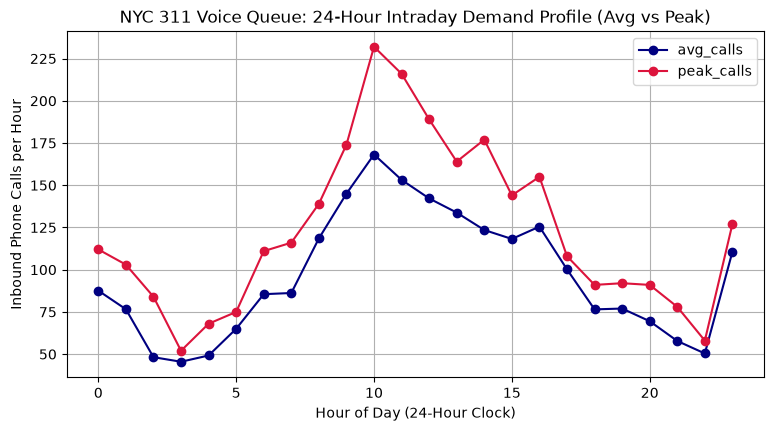

In [5]:
daily_hourly = phone_df.groupby(["date", "hour"])["unique_key"].count().reset_index(name="calls")

hourly_profile = daily_hourly.groupby("hour")["calls"].agg(
    avg_calls="mean",
    peak_calls="max"
).round(1)

hourly_profile.plot(
    kind="line",
    marker="o",
    color=["navy", "crimson"],
    title="NYC 311 Voice Queue: 24-Hour Intraday Demand Profile (Avg vs Peak)",
    xlabel="Hour of Day (24-Hour Clock)",
    ylabel="Inbound Phone Calls per Hour",
    grid=True,
    figsize=(9, 4.5)
)

hourly_profile.T

In [6]:
def solve_erlang_fte(calls, aht=300, target_sl=0.80, target_sec=20, shrinkage=0.25):
    A = (calls * aht) / 3600
    agents = math.floor(A) + 1
    
    while True:
        rho = A / agents
        top = (A ** agents / math.factorial(agents)) * (1 / (1 - rho))
        bottom_sum = sum([(A ** k) / math.factorial(k) for k in range(agents)])
        prob_wait = top / (bottom_sum + top)
        sl = 1 - (prob_wait * math.exp(-(agents - A) * (target_sec / aht)))
        
        if sl >= target_sl:
            return round(agents / (1 - shrinkage), 1)
        agents += 1

hourly_profile["baseline_fte"] = [solve_erlang_fte(c) for c in hourly_profile["avg_calls"]]
hourly_profile["peak_fte"] = [solve_erlang_fte(c) for c in hourly_profile["peak_calls"]]
hourly_profile["ai_deflected_peak_fte"] = [solve_erlang_fte(c * 0.75) for c in hourly_profile["peak_calls"]]
hourly_profile["ai_fte_saved_at_peak"] = round(hourly_profile["peak_fte"] - hourly_profile["ai_deflected_peak_fte"], 1)

print(f"10 AM Peak Hour FTEs (No AI): {hourly_profile.loc[10, 'peak_fte']} FTEs")
print(f"10 AM Peak Hour FTEs (With 25% AI Deflection): {hourly_profile.loc[10, 'ai_deflected_peak_fte']} FTEs")
print(f"Peak Roster Headcount Saved by AI Deflection: {hourly_profile.loc[10, 'ai_fte_saved_at_peak']} FTEs")
hourly_profile

10 AM Peak Hour FTEs (No AI): 32.0 FTEs
10 AM Peak Hour FTEs (With 25% AI Deflection): 25.3 FTEs
Peak Roster Headcount Saved by AI Deflection: 6.7 FTEs


,avg_calls,peak_calls,baseline_fte,peak_fte,ai_deflected_peak_fte,ai_fte_saved_at_peak
hour,,,,,,
0,87.6,112,14.7,17.3,13.3,4.0
1,76.6,103,13.3,16.0,13.3,2.7
2,48.2,84,9.3,13.3,10.7,2.6
3,45.5,52,9.3,9.3,8.0,1.3
4,49.2,68,9.3,12.0,9.3,2.7
5,65.0,75,10.7,12.0,10.7,1.3
6,85.5,111,13.3,17.3,13.3,4.0
7,86.2,116,14.7,17.3,14.7,2.6
8,118.5,139,18.7,21.3,16.0,5.3


Exported nyc_311_hourly_erlang_capacity.csv for Tableau & GitHub!


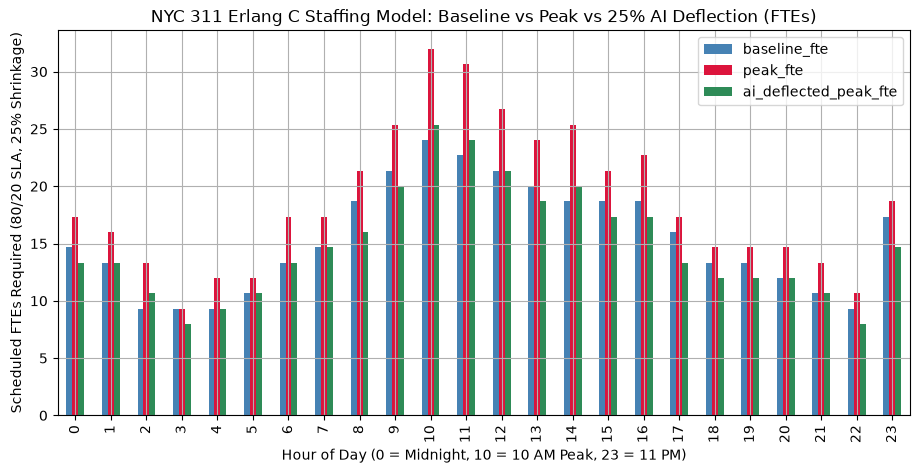

In [7]:
hourly_profile[["baseline_fte", "peak_fte", "ai_deflected_peak_fte"]].plot(
    kind="bar",
    color=["steelblue", "crimson", "seagreen"],
    title="NYC 311 Erlang C Staffing Model: Baseline vs Peak vs 25% AI Deflection (FTEs)",
    xlabel="Hour of Day (0 = Midnight, 10 = 10 AM Peak, 23 = 11 PM)",
    ylabel="Scheduled FTEs Required (80/20 SLA, 25% Shrinkage)",
    grid=True,
    figsize=(11, 5)
)

hourly_profile.reset_index().to_csv("nyc_311_hourly_erlang_capacity.csv", index=False)
print("Exported nyc_311_hourly_erlang_capacity.csv for Tableau & GitHub!")